# Actividad 5 (Evaluación): regresión lineal simple, múltiple y logística

Este notebook corresponde al repositorio Actividad 5 (Evaluación) y trabaja con el archivo Datos_Complementarios_CLV.xlsx, que contiene el inventario de una distribuidora de productos dentales (artículo, marca, almacén, existencias y valor del inventario).

El trabajo sigue este orden:
- Preprocesamiento: nulos, outliers y transformaciones.
- Regresión lineal simple con la pareja de variables más correlacionada.
- Regresión lineal múltiple y comparación contra el modelo simple.
- Regresión logística con reponderación de clases y oversampling, y después con variables dicotómicas.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.utils import resample
from sklearn.metrics import (confusion_matrix, classification_report, roc_auc_score,
                             accuracy_score, ConfusionMatrixDisplay)

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

ARCHIVO = "Datos_Complementarios_CLV.xlsx"   # el archivo debe estar en la misma carpeta que el notebook
RANDOM_STATE = 42

# Carga y exploración de la base

In [2]:
# Se lee el Excel y se revisa su tamaño, primeras filas y tipos de dato
df = pd.read_excel(ARCHIVO)
df.columns = df.columns.str.strip()

print("Dimensiones:", df.shape)
display(df.head())
df.info()

Dimensiones: (2951, 6)


,articulo,nombre_articulo,marca,almacen,existencias,valor_inventario
0,5804,CAMEO PRESS INGOT BOX HT A2,Aidite,Almacén General,1396,431773.71
1,5816,CAMEO PRESS INGOT BOX LT A1,Aidite,Almacén General,1043,316841.19
2,5762,CAMEO MILL BLOCS BOX C14 HT B1,Aidite,Almacén General,893,326871.85
3,212202,DIENTES HU TABLILLA ZAHN4ALL ANTERIOR SUPERIOR...,Huge,Almacén General,893,10368.49
4,5819,CAMEO PRESS INGOT BOX LT A2,Aidite,Almacén General,857,264454.69


<class 'pandas.DataFrame'>
RangeIndex: 2951 entries, 0 to 2950
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   articulo          2951 non-null   int64  
 1   nombre_articulo   2951 non-null   str    
 2   marca             2951 non-null   str    
 3   almacen           2951 non-null   str    
 4   existencias       2951 non-null   int64  
 5   valor_inventario  2951 non-null   float64
dtypes: float64(1), int64(2), str(3)
memory usage: 273.4 KB


## Análisis de la estructura

- La base tiene 2951 filas y 6 columnas, sin ningún valor nulo en el momento de la carga.
- Hay tres columnas de texto (nombre del artículo, marca y almacén), dos enteras (artículo y existencias) y una decimal (valor del inventario).
- Cada fila es un producto distinto, por lo que la base describe un inventario y no transacciones de clientes.
- Solo existen dos medidas numéricas reales: existencias y valor del inventario. La columna artículo es un código, aunque venga como número.

In [3]:
# Resumen estadístico de todas las columnas
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
articulo,2951.0,NaN,NaN,NaN,3827014.674348,13208297.800076,3488.0,9084.5,11996.0,211975.5,71342123.0
nombre_articulo,2951,2951,CAMEO PRESS INGOT BOX HT A2,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marca,2951,26,Vita,1810,NaN,NaN,NaN,NaN,NaN,NaN,NaN
almacen,2951,1,Almacén General,2951,NaN,NaN,NaN,NaN,NaN,NaN,NaN
existencias,2951.0,NaN,NaN,NaN,27.585564,82.059392,1.0,3.0,7.0,15.0,1396.0
valor_inventario,2951.0,NaN,NaN,NaN,23050.915507,134279.408206,0.0,1053.28,2340.51,6180.99,3644807.19


## Análisis del resumen estadístico

- La marca Vita domina el inventario con 1810 de los 2951 productos (alrededor del 61 %), y en total hay 26 marcas.
- El almacén tiene un único valor (Almacén General), así que no aporta información para comparar y se eliminará.
- Las existencias tienen una media de 27.6 unidades contra una mediana de 7, con un máximo de 1396. Es decir, la mayoría de los productos tiene pocas piezas y unos cuantos tienen muchísimas.
- El valor del inventario tiene una media de 23,051 contra una mediana de 2,340, con un máximo de más de 3.6 millones. La media tan por encima de la mediana indica una distribución con cola larga a la derecha.
- Ambas variables numéricas tienen asimetría fuerte, por lo que será necesario transformarlas antes de modelar.

# Preprocesamiento

## Limpieza inicial

In [4]:
# Duplicados: se revisan antes de quitar los códigos para no confundir productos distintos
duplicados = df.duplicated().sum()
df = df.drop_duplicates()

# Columnas identificadoras (no miden nada) y columnas constantes (no aportan información)
ids = ["articulo", "nombre_articulo"]
df = df.drop(columns=ids)
constantes = [c for c in df.columns if df[c].nunique() <= 1]
df = df.drop(columns=constantes)

# Texto uniforme: sin espacios sobrantes y con la misma capitalización
for c in df.select_dtypes(exclude="number").columns:
    df[c] = df[c].astype(str).str.strip().str.title().replace({"Nan": np.nan, "None": np.nan, "": np.nan})

print("Filas duplicadas eliminadas:", duplicados)
print("Columnas identificadoras eliminadas:", ids)
print("Columnas constantes eliminadas:", constantes)
print("Columnas que quedan:", list(df.columns))

Filas duplicadas eliminadas: 0
Columnas identificadoras eliminadas: ['articulo', 'nombre_articulo']
Columnas constantes eliminadas: ['almacen']
Columnas que quedan: ['marca', 'existencias', 'valor_inventario']


## Análisis de la limpieza

- No había filas duplicadas, así que no se perdió ningún registro.
- Se eliminaron el código y el nombre del artículo porque solo identifican al producto y no representan una cantidad que tenga sentido modelar.
- Se eliminó el almacén por tener un solo valor.
- Quedan tres columnas útiles: marca (categórica), existencias y valor del inventario (numéricas).

## Valores nulos

In [5]:
# Conteo de nulos por columna
nulos = pd.DataFrame({"nulos": df.isna().sum(), "porcentaje": (df.isna().mean() * 100).round(2)})
display(nulos)

# Regla: más de 50 % de nulos se elimina la columna; si no, se imputa
# (mediana para numéricas porque resiste valores extremos, moda para categóricas)
muchos_nulos = nulos[nulos["porcentaje"] > 50].index.tolist()
df = df.drop(columns=muchos_nulos)

for c in df.columns:
    if df[c].isna().any():
        relleno = df[c].median() if pd.api.types.is_numeric_dtype(df[c]) else df[c].mode()[0]
        df[c] = df[c].fillna(relleno)

print("Columnas eliminadas por exceso de nulos:", muchos_nulos)
print("Nulos restantes:", df.isna().sum().sum())

,nulos,porcentaje
marca,0,0.0
existencias,0,0.0
valor_inventario,0,0.0


Columnas eliminadas por exceso de nulos: []
Nulos restantes: 0


## Análisis de los nulos

- Ninguna columna tiene valores nulos, por lo que no fue necesario eliminar columnas ni imputar valores.
- Se deja la regla de imputación en el código por si la base se actualiza con datos incompletos.
- Al no haber nulos, todas las filas se conservan para el análisis.

## Transformación logarítmica

In [6]:
# Asimetría (skewness) de las variables numéricas antes de transformar
num_cols = list(df.select_dtypes(include="number").columns)
asimetria = df[num_cols].skew()
display(asimetria.round(3).to_frame("skewness original"))

# Si |skewness| > 1 y no hay negativos, se aplica log(1 + x) y se reemplaza la columna original
transformadas = []
for c in num_cols:
    if abs(asimetria[c]) > 1 and df[c].min() >= 0:
        df[f"log_{c}"] = np.log1p(df[c])
        df = df.drop(columns=c)
        transformadas.append(c)

num_cols = list(df.select_dtypes(include="number").columns)
cat_cols = list(df.select_dtypes(exclude="number").columns)
print("Variables transformadas:", transformadas)
print("Numéricas:", num_cols)
print("Categóricas:", cat_cols)

,skewness original
existencias,7.213
valor_inventario,16.601


Variables transformadas: ['existencias', 'valor_inventario']
Numéricas: ['log_existencias', 'log_valor_inventario']
Categóricas: ['marca']


## Análisis de la transformación

- Antes de transformar, la asimetría de las existencias era de 7.21 y la del valor del inventario de 16.60, valores muy por encima del límite de 1 que se usa como criterio.
- Las dos variables se transformaron con el logaritmo natural de uno más el valor. Se usa uno más x porque el valor del inventario tiene mínimos de cero y el logaritmo de cero no existe.
- Esta transformación reduce el peso de los valores gigantes y vuelve más lineal la relación entre las variables, lo que ayuda a los modelos de regresión.
- A partir de aquí se trabaja con el logaritmo de existencias y el logaritmo del valor del inventario.

## Outliers

,variable,outliers,lim_inf,lim_sup
0,log_existencias,138,-0.693147,4.852030
1,log_valor_inventario,232,4.307440,11.382568


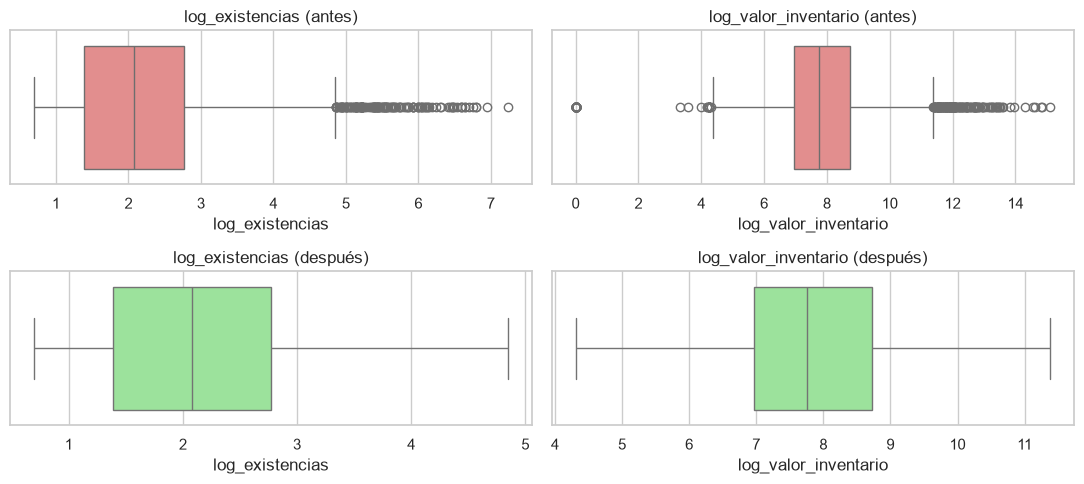

Outliers restantes: 0


In [7]:
# Límites del método IQR: Q1 - 1.5*IQR y Q3 + 1.5*IQR
def limites_iqr(serie):
    q1, q3 = serie.quantile([.25, .75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

filas = []
for c in num_cols:
    li, ls = limites_iqr(df[c])
    filas.append([c, ((df[c] < li) | (df[c] > ls)).sum(), li, ls])
outliers = pd.DataFrame(filas, columns=["variable", "outliers", "lim_inf", "lim_sup"])
display(outliers)

# Boxplots antes (arriba) y después (abajo) de acotar los valores a los límites
fig, axes = plt.subplots(2, len(num_cols), figsize=(5.5 * len(num_cols), 5))
for j, c in enumerate(num_cols):
    sns.boxplot(x=df[c], ax=axes[0, j], color="lightcoral")
    axes[0, j].set_title(f"{c} (antes)")

# En lugar de borrar filas se acotan (winsorización) para no perder registros
for _, r in outliers.iterrows():
    df[r["variable"]] = df[r["variable"]].clip(r["lim_inf"], r["lim_sup"])

for j, c in enumerate(num_cols):
    sns.boxplot(x=df[c], ax=axes[1, j], color="lightgreen")
    axes[1, j].set_title(f"{c} (después)")
plt.tight_layout()
plt.show()

restantes = sum(((df[c] < limites_iqr(df[c])[0]) | (df[c] > limites_iqr(df[c])[1])).sum() for c in num_cols)
print("Outliers restantes:", restantes)

## Análisis de los outliers

- Con el método IQR se detectaron 138 valores atípicos en el logaritmo de existencias y 232 en el logaritmo del valor del inventario.
- En existencias el límite superior equivale a unas 127 piezas, y en valor del inventario los límites equivalen aproximadamente a 73 y 87 mil, así que son productos con mucho inventario o con precios muy altos o muy bajos frente al resto.
- No se eliminaron filas: los valores extremos se acotaron al límite más cercano. Así se conserva la información de que esos productos son grandes sin que distorsionen la recta de regresión.
- En los boxplots de abajo ya no aparecen puntos fuera de los bigotes, y el conteo de outliers restantes es cero.
- Una consecuencia de acotar es que se acumulan varios productos justo en el límite superior, algo que se verá en las gráficas del modelo.

## Distribución final

,skewness final
log_existencias,0.766
log_valor_inventario,0.286


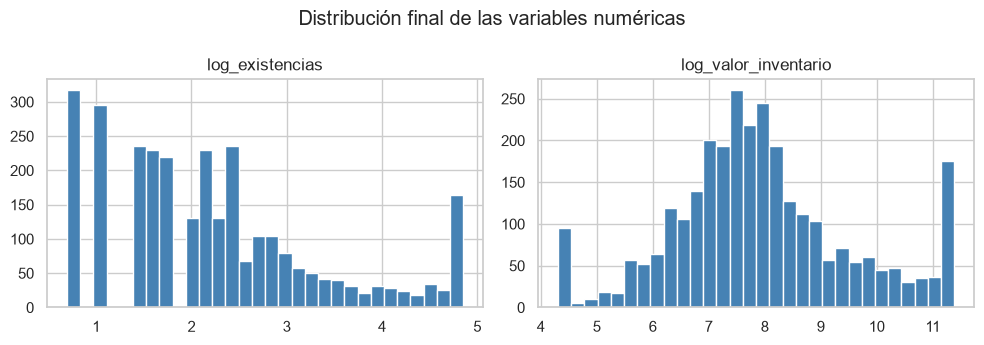

In [8]:
# Asimetría e histogramas después de transformar y acotar
display(df[num_cols].skew().round(3).to_frame("skewness final"))

df[num_cols].hist(figsize=(5 * len(num_cols), 3.5), bins=30, layout=(1, len(num_cols)), color="steelblue")
plt.suptitle("Distribución final de las variables numéricas")
plt.tight_layout()
plt.show()

## Análisis de la distribución final

- La asimetría bajó a 0.77 en existencias y a 0.29 en valor del inventario, ambas dentro de un rango aceptable para modelar.
- El logaritmo del valor del inventario tiene una forma parecida a una campana centrada alrededor de 7.5, con barras más altas en los extremos que corresponden a los valores acotados.
- El logaritmo de existencias sigue concentrado en valores bajos, porque la mayoría de los productos tiene pocas piezas, y muestra barras separadas porque las existencias son números enteros.
- Con esta forma las variables ya son adecuadas para las regresiones.

# Regresión lineal simple

## Análisis de correlación

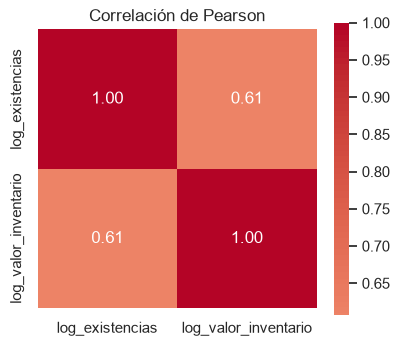

,var1,var2,r,|r|
0,log_existencias,log_valor_inventario,0.606942,0.606942


Variable dependiente (Y): log_valor_inventario
Variable independiente (X): log_existencias
Correlación r = 0.6069


In [9]:
# Matriz de correlación de Pearson entre las variables numéricas
corr = df[num_cols].corr()
plt.figure(figsize=(4.5, 3.8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlación de Pearson")
plt.show()

# Pares de variables ordenados por correlación absoluta
pares = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().dropna().reset_index()
pares.columns = ["var1", "var2", "r"]
pares["|r|"] = pares["r"].abs()
pares = pares.sort_values("|r|", ascending=False)
display(pares)

# La pareja más correlacionada define el modelo: Y es la variable de valor y X la otra
v1, v2 = pares.iloc[0][["var1", "var2"]]
y_var = next((v for v in (v1, v2) if "valor" in v), v2)
x_var = v2 if y_var == v1 else v1
print(f"Variable dependiente (Y): {y_var}")
print(f"Variable independiente (X): {x_var}")
print(f"Correlación r = {corr.loc[x_var, y_var]:.4f}")

## Análisis de la correlación

- La correlación entre el logaritmo de existencias y el logaritmo del valor del inventario es de 0.607, una relación positiva de intensidad moderada.
- Como solo hay dos variables numéricas, esta es la única pareja posible y por lo tanto la de mayor correlación de la base.
- Se toma el valor del inventario como variable a explicar y las existencias como variable explicativa, porque tiene sentido que un producto con más piezas acumule más valor.
- Una correlación de 0.61 indica que las existencias explican una parte importante del valor, pero no todo. Falta el precio de cada producto, que no está en la base.

## Modelo de regresión lineal simple

                             OLS Regression Results                             
Dep. Variable:     log_valor_inventario   R-squared:                       0.368
Model:                              OLS   Adj. R-squared:                  0.368
Method:                   Least Squares   F-statistic:                     1720.
Date:                  Mon, 19 Oct 2026   Prob (F-statistic):          1.44e-296
Time:                          22:10:41   Log-Likelihood:                -4904.5
No. Observations:                  2951   AIC:                             9813.
Df Residuals:                      2949   BIC:                             9825.
Df Model:                             1                                         
Covariance Type:              nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               5.

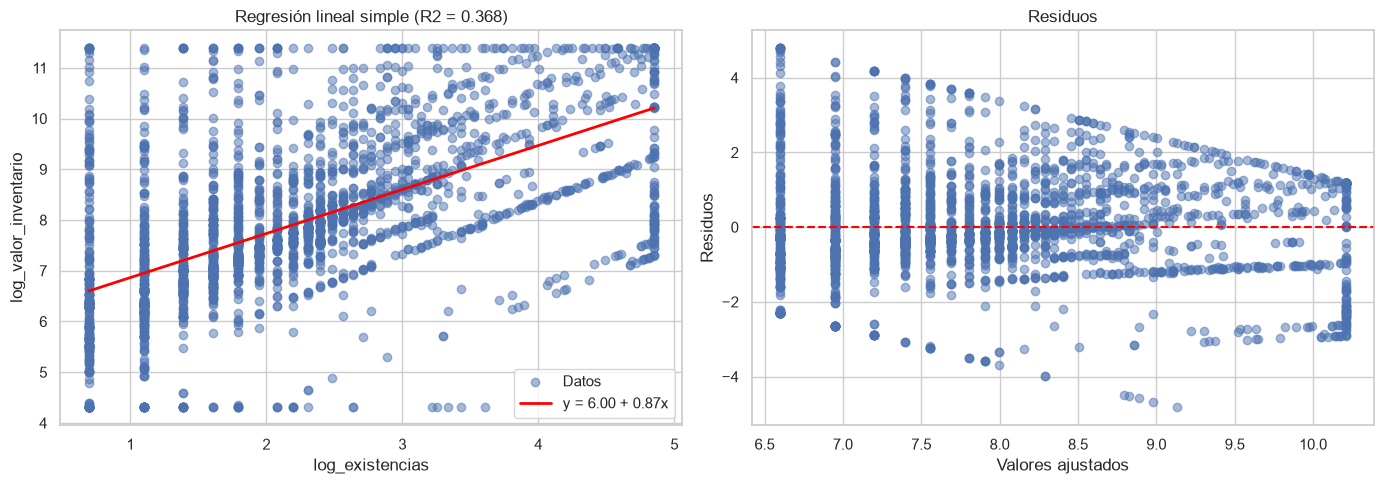

In [10]:
# Ajuste por mínimos cuadrados ordinarios: Y = b0 + b1 * X
X_s = sm.add_constant(df[[x_var]])
modelo_simple = sm.OLS(df[y_var], X_s).fit()
print(modelo_simple.summary())

b0, b1 = modelo_simple.params
print(f"\nEcuación: {y_var} = {b0:.4f} + ({b1:.4f}) * {x_var}")
print(f"R2 = {modelo_simple.rsquared:.4f} | R = {np.sqrt(modelo_simple.rsquared):.4f}")
print(f"Como ambas variables están en logaritmo, b1 es una elasticidad: si las existencias suben 1 %, "
      f"el valor del inventario sube aproximadamente {b1:.2f} %.")

# Recta sobre los datos (izquierda) y residuos contra valores ajustados (derecha)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(df[x_var], df[y_var], alpha=.5, label="Datos")
xs = np.linspace(df[x_var].min(), df[x_var].max(), 100)
ax[0].plot(xs, b0 + b1 * xs, color="red", lw=2, label=f"y = {b0:.2f} + {b1:.2f}x")
ax[0].set_xlabel(x_var); ax[0].set_ylabel(y_var); ax[0].legend()
ax[0].set_title(f"Regresión lineal simple (R2 = {modelo_simple.rsquared:.3f})")

ax[1].scatter(modelo_simple.fittedvalues, modelo_simple.resid, alpha=.5)
ax[1].axhline(0, color="red", ls="--")
ax[1].set_xlabel("Valores ajustados"); ax[1].set_ylabel("Residuos"); ax[1].set_title("Residuos")
plt.tight_layout()
plt.show()

## Análisis del modelo simple

- La ecuación es: log del valor del inventario = 5.9981 + 0.8677 por el log de existencias.
- El coeficiente de existencias es significativo (p menor a 0.001, estadístico t de 41.5), y el modelo completo también lo es (F de 1720).
- Como las dos variables están en logaritmo, el coeficiente se lee como elasticidad: si las existencias aumentan 1 %, el valor del inventario aumenta cerca de 0.87 %.
- El R cuadrado es de 0.368, es decir, las existencias explican alrededor del 37 % de la variación del valor. El 63 % restante depende de otros factores, sobre todo del precio y de la marca.
- En la gráfica de la izquierda los puntos forman líneas diagonales. Cada línea corresponde a productos con un precio unitario fijo: si ese precio no cambia, el valor crece proporcionalmente con las piezas. Productos con precios distintos quedan en líneas distintas, y eso es lo que la recta única no puede capturar.
- En los residuos se nota que la dispersión es mayor cuando los valores ajustados son bajos y se reduce hacia la derecha, así que la varianza no es constante. Además, la prueba de Jarque-Bera indica que los residuos no son perfectamente normales (asimetría 0.45 y curtosis 4.8).
- Con casi 3000 datos los coeficientes siguen siendo confiables, pero el modelo simple se queda corto y justifica probar un modelo múltiple.

# Regresión lineal múltiple

## Búsqueda del mejor modelo

In [11]:
# Variables explicativas: todas las demás; la marca se convierte en columnas 0/1 (dummies)
X_m = pd.get_dummies(df.drop(columns=[y_var]), drop_first=True).astype(float)
X_m = X_m.loc[:, X_m.std() > 0]
y_m = df[y_var]

# La marca que no aparece como columna es la categoría de referencia
referencia = [m for m in sorted(df["marca"].unique()) if f"marca_{m}" not in X_m.columns]
print("Marca de referencia:", referencia)

def calcular_vif(X):
    Xc = sm.add_constant(X)
    return pd.Series([variance_inflation_factor(Xc.values, i + 1) for i in range(X.shape[1])], index=X.columns)

# Paso 1: se quita la variable con mayor VIF mientras alguna supere 10 (multicolinealidad)
while X_m.shape[1] > 1:
    vif = calcular_vif(X_m)
    if vif.max() <= 10:
        break
    peor = vif.idxmax()
    if peor == x_var:
        peor = vif.drop(x_var).idxmax()
    print(f"Se elimina {peor} (VIF = {vif.max():.1f})")
    X_m = X_m.drop(columns=peor)

# Paso 2: eliminación hacia atrás, se quita la variable con mayor p-value hasta que todas sean significativas
while True:
    mod = sm.OLS(y_m, sm.add_constant(X_m)).fit()
    p = mod.pvalues.drop("const")
    if p.max() < 0.05 or X_m.shape[1] == 1:
        break
    print(f"Se elimina {p.idxmax()} (p = {p.max():.4f})")
    X_m = X_m.drop(columns=p.idxmax())

modelo_multiple = mod
print(modelo_multiple.summary())
print(f"\nVIF máximo del modelo final: {calcular_vif(X_m).max():.2f}")

Marca de referencia: ['3Dgar']
Se elimina marca_Vita (VIF = 233.8)
Se elimina marca_Scheftner (p = 0.8452)
Se elimina marca_Parmex (p = 0.1337)
Se elimina marca_Dess (p = 0.1045)
Se elimina marca_Schick (p = 0.0915)
                             OLS Regression Results                             
Dep. Variable:     log_valor_inventario   R-squared:                       0.644
Model:                              OLS   Adj. R-squared:                  0.642
Method:                   Least Squares   F-statistic:                     252.8
Date:                  Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                          22:10:49   Log-Likelihood:                -4056.6
No. Observations:                  2951   AIC:                             8157.
Df Residuals:                      2929   BIC:                             8289.
Df Model:                            21                                         
Covariance Type:              nonrobust                

## Análisis del modelo múltiple

- Se partió de existencias y de una columna 0/1 por cada marca. Primero se quitó la marca Vita por tener un VIF de 233.8 (multicolinealidad muy alta), y después se quitaron por no ser significativas las marcas Scheftner, Parmex, Dess y Schick.
- Las marcas eliminadas pasan a formar parte del grupo de referencia junto con la marca omitida desde el inicio, de modo que cada coeficiente de marca se lee como la diferencia frente a ese grupo.
- El modelo final tiene 21 variables explicativas (existencias y 20 marcas), todas significativas, y un VIF máximo cercano a 1.5, por lo que ya no hay multicolinealidad.
- El R cuadrado sube a 0.644 y el ajustado a 0.642, contra 0.368 del modelo simple. La marca explica por sí sola una gran parte del valor que faltaba.
- El coeficiente de existencias es de 0.962: a igualdad de marca, 1 % más de piezas se asocia con alrededor de 0.96 % más de valor, casi una relación proporcional.
- Las marcas con los coeficientes más altos son Durr Dental (4.66), Apple (3.97) y Exocad (3.38), que son marcas de productos caros. Huge es la única con coeficiente negativo (-2.35), lo que indica productos de muy bajo valor unitario frente al grupo de referencia.
- Los residuos siguen sin ser normales (curtosis de 7.3), con colas pesadas, pero la asimetría es casi cero y el Durbin-Watson de 1.48 es aceptable.

## Comparación contra el modelo simple

,Simple,Múltiple
const,5.9981,5.4148
log_existencias,0.8677,0.9620
R2,0.3684,0.6445
R2 ajustado,0.3682,0.6419
AIC,9813.0347,8157.1009
Variables,1.0000,21.0000


El coeficiente de log_existencias pasa de 0.8677 a 0.9620, un cambio de 10.9 %.


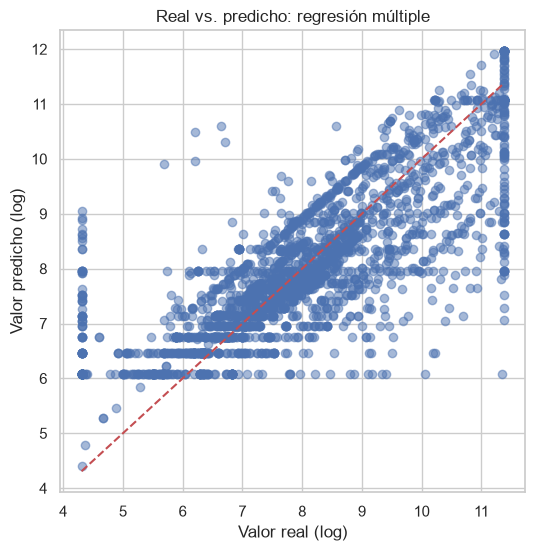

In [12]:
# Se comparan los coeficientes que comparten ambos modelos y las medidas de ajuste
comp = pd.DataFrame({"Simple": modelo_simple.params[["const", x_var]],
                     "Múltiple": modelo_multiple.params[["const", x_var]]})
comp.loc["R2"] = [modelo_simple.rsquared, modelo_multiple.rsquared]
comp.loc["R2 ajustado"] = [modelo_simple.rsquared_adj, modelo_multiple.rsquared_adj]
comp.loc["AIC"] = [modelo_simple.aic, modelo_multiple.aic]
comp.loc["Variables"] = [1, X_m.shape[1]]
display(comp.round(4))

s, m = modelo_simple.params[x_var], modelo_multiple.params[x_var]
print(f"El coeficiente de {x_var} pasa de {s:.4f} a {m:.4f}, un cambio de {100 * (m - s) / abs(s):.1f} %.")

# Valores reales contra predichos del modelo múltiple
plt.figure(figsize=(6, 6))
plt.scatter(y_m, modelo_multiple.fittedvalues, alpha=.5)
lims = [y_m.min(), y_m.max()]
plt.plot(lims, lims, "r--")
plt.xlabel("Valor real (log)"); plt.ylabel("Valor predicho (log)")
plt.title("Real vs. predicho: regresión múltiple")
plt.show()

## Análisis de la comparación

- El coeficiente de existencias aumenta de 0.8677 en el modelo simple a 0.9620 en el múltiple, un cambio de 10.9 %. Al controlar por la marca, el efecto de las existencias se aclara y se acerca a una relación proporcional.
- La constante baja de 5.998 a 5.415 porque ahora parte del nivel de valor lo explican las marcas.
- El R cuadrado ajustado casi se duplica (de 0.368 a 0.642), y el AIC baja de 9813 a 8157. Una caída de más de 1600 puntos de AIC es una mejora muy grande, aun penalizando por tener más variables.
- En la gráfica de real contra predicho, los puntos siguen la diagonal en la parte central, lo que confirma que el modelo acierta en general. Se ven franjas horizontales abajo, que son productos de pocas piezas a los que el modelo les asigna el mismo valor, y una columna vertical a la derecha, que corresponde a los valores acotados en el límite superior.
- Conclusión: el modelo múltiple es claramente mejor que el simple. Aun así queda cerca de un 36 % de variación sin explicar, probablemente por la falta del precio unitario de cada producto.

# Regresión logística

## Variable dicotómica

,n,%
log_valor_inventario,,
0,2213,74.99
1,738,25.01


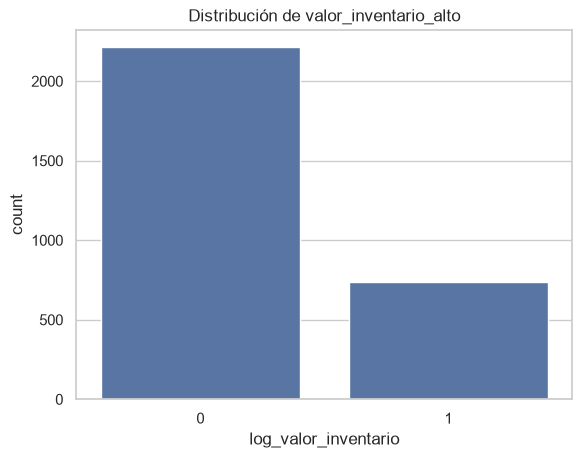

In [13]:
# La base no trae una variable dicotómica, así que se crea una:
# 1 si el valor del inventario del producto está en el 25 % más alto
y_log_var = "valor_inventario_alto"
y_log = (df[y_var] > df[y_var].quantile(.75)).astype(int)

conteo = pd.DataFrame({"n": y_log.value_counts(), "%": (y_log.value_counts(normalize=True) * 100).round(2)})
display(conteo)

sns.countplot(x=y_log)
plt.title(f"Distribución de {y_log_var}")
plt.show()

## Análisis de la variable dicotómica

- Se definió valor_inventario_alto como 1 cuando el producto está en el 25 % superior de valor y 0 en caso contrario.
- Quedaron 2213 productos en la clase 0 (74.99 %) y 738 en la clase 1 (25.01 %), una proporción de 3 a 1.
- Este desbalance es justo el caso donde conviene aplicar reponderación de clases u oversampling, porque un modelo sin ajuste tiende a favorecer a la clase mayoritaria.
- Para no hacer trampa, el logaritmo del valor del inventario se excluye de los predictores, ya que de ahí se construyó la variable objetivo.

## Modelos con reponderación de clases y oversampling

Entrenamiento tras oversampling: {0: 1660, 1: 1660}


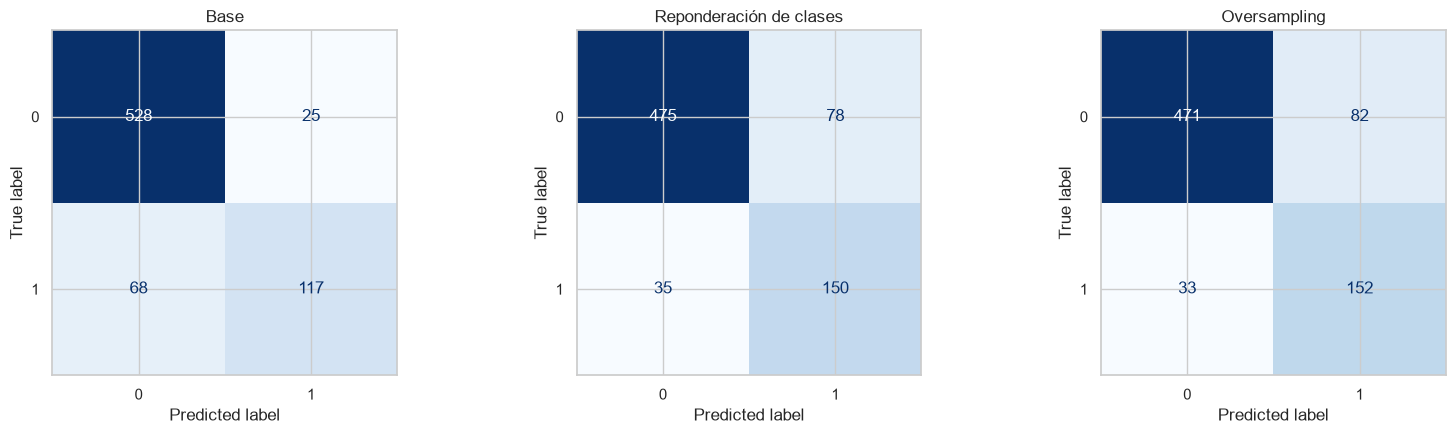

,Accuracy,Precisión (1),Recall (1),F1 (1),AUC
Modelo,,,,,
Base,0.8740,0.8239,0.6324,0.7156,0.9074
Reponderación de clases,0.8469,0.6579,0.8108,0.7264,0.9084
Oversampling,0.8442,0.6496,0.8216,0.7255,0.9082


In [14]:
# Predictores: existencias y marcas (sin la variable de la que sale el objetivo)
X_l = pd.get_dummies(df.drop(columns=[y_var]), drop_first=True).astype(float)
X_l = X_l.loc[:, X_l.std() > 0]

# División entrenamiento y prueba conservando la proporción de clases, y estandarización
X_tr, X_te, y_tr, y_te = train_test_split(X_l, y_log, test_size=.25, stratify=y_log, random_state=RANDOM_STATE)
scaler = StandardScaler().fit(X_tr)
X_tr_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_te)

# Oversampling: solo en entrenamiento, se repiten al azar casos de la clase minoritaria hasta igualar a la mayoritaria
tr = pd.DataFrame(X_tr_s, columns=X_l.columns)
tr["y"] = y_tr.values
clase_mayor = tr["y"].mode()[0]
mayor, menor = tr[tr.y == clase_mayor], tr[tr.y != clase_mayor]
menor_up = resample(menor, replace=True, n_samples=len(mayor), random_state=RANDOM_STATE)
tr_os = pd.concat([mayor, menor_up]).sample(frac=1, random_state=RANDOM_STATE)
print("Entrenamiento tras oversampling:", tr_os["y"].value_counts().to_dict())

# Tres modelos: base, con pesos por clase y con datos remuestreados
modelos = {
    "Base": LogisticRegression(max_iter=1000).fit(X_tr_s, y_tr),
    "Reponderación de clases": LogisticRegression(max_iter=1000, class_weight="balanced").fit(X_tr_s, y_tr),
    "Oversampling": LogisticRegression(max_iter=1000).fit(tr_os.drop(columns="y").values, tr_os["y"]),
}

# Métricas sobre el conjunto de prueba y matrices de confusión
res = []
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (nombre, m) in zip(axes, modelos.items()):
    pred = m.predict(X_te_s)
    prob = m.predict_proba(X_te_s)[:, 1]
    rep = classification_report(y_te, pred, output_dict=True, zero_division=0)
    res.append([nombre, accuracy_score(y_te, pred), rep["1"]["precision"], rep["1"]["recall"],
                rep["1"]["f1-score"], roc_auc_score(y_te, prob)])
    ConfusionMatrixDisplay(confusion_matrix(y_te, pred)).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

tabla = pd.DataFrame(res, columns=["Modelo", "Accuracy", "Precisión (1)", "Recall (1)", "F1 (1)", "AUC"]).set_index("Modelo")
display(tabla.round(4))

## Análisis de los modelos balanceados

- El modelo base tiene el mejor accuracy (0.874), pero eso engaña: su recall de la clase 1 es de solo 0.632, es decir, deja pasar más de un tercio de los productos de valor alto.
- Con reponderación de clases el recall sube a 0.811 y con oversampling a 0.822. A cambio la precisión baja de 0.824 a 0.658 y 0.650, porque ahora el modelo marca más productos como de valor alto y se equivoca más veces.
- El F1 de la clase 1, que equilibra precisión y recall, mejora de 0.716 en el base a 0.726 con reponderación y 0.726 con oversampling. La diferencia entre las dos técnicas es mínima.
- El AUC es prácticamente igual en los tres modelos (alrededor de 0.908), lo que indica que la capacidad de ordenar productos de menor a mayor probabilidad es la misma y que balancear solo mueve el punto de corte.
- Las matrices de confusión reflejan lo mismo: el modelo base tiene más falsos negativos, y los balanceados cambian esos errores por más falsos positivos.
- Se elige la reponderación de clases por tener el mejor F1 y porque es más sencilla, ya que no duplica datos. Si lo importante fuera no dejar escapar productos de valor alto, el oversampling también sería buena opción por su recall.

Mejor modelo: Reponderación de clases


,coef,odds_ratio
marca_Huge,-0.9065,0.4039
marca_Vita,-0.6426,0.5259
marca_Dess,-0.2194,0.8030
marca_Cyberpuerta,-0.1341,0.8745
marca_Parmex,-0.1292,0.8788
marca_Scheftner,-0.0974,0.9072
marca_Arma Dental,-0.0687,0.9336
marca_Creation,0.0620,1.0639
marca_Dentine,0.0738,1.0766
marca_Schick,0.0759,1.0788


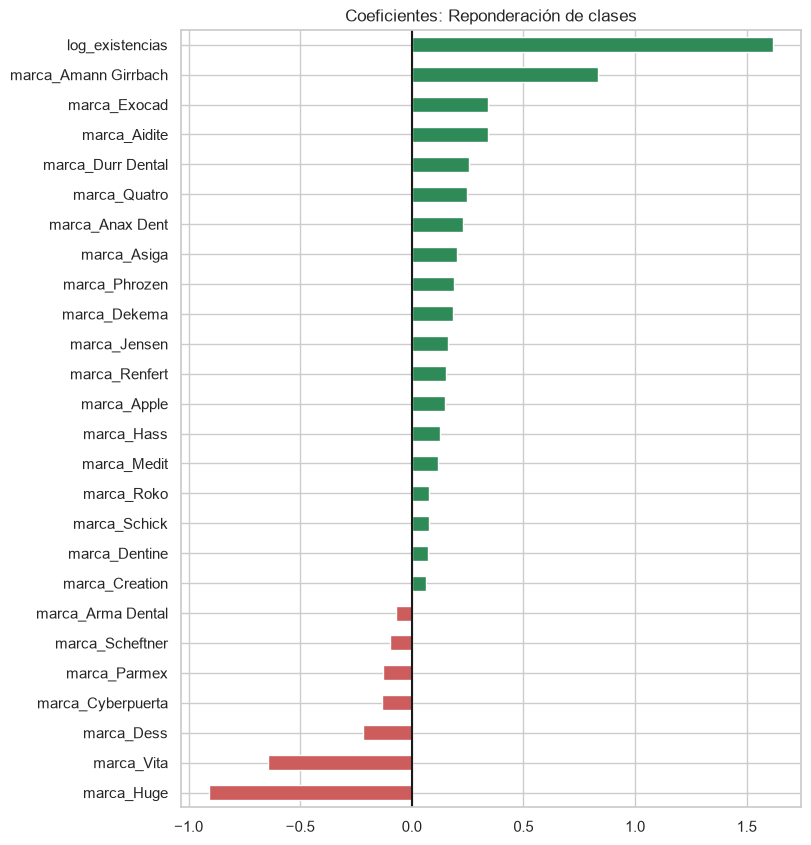

In [15]:
# Coeficientes del mejor modelo según F1 (variables estandarizadas, así que son comparables entre sí)
mejor = tabla["F1 (1)"].idxmax()
coef = pd.DataFrame({"coef": modelos[mejor].coef_[0], "odds_ratio": np.exp(modelos[mejor].coef_[0])},
                    index=X_l.columns).sort_values("coef")
print(f"Mejor modelo: {mejor}")
display(coef.round(4))

coef["coef"].plot.barh(figsize=(8, 0.35 * len(coef) + 1), color=np.where(coef["coef"] > 0, "seagreen", "indianred"))
plt.axvline(0, color="k")
plt.title(f"Coeficientes: {mejor}")
plt.show()

## Análisis de los coeficientes

- La variable más influyente es el logaritmo de existencias, con un coeficiente de 1.618 y un odds ratio de 5.04: por cada aumento de una desviación estándar en las existencias, los momios de que el producto sea de valor alto se multiplican por 5.
- Entre las marcas, Amann Girrbach es la que más favorece un valor alto (odds ratio de 2.30), seguida de Exocad y Aidite (1.41 aproximadamente).
- Huge (odds ratio de 0.40) y Vita (0.53) son las marcas que más reducen la probabilidad de estar en el grupo de valor alto. Es coherente con el modelo múltiple, donde Huge tenía el coeficiente más negativo.
- El resto de las marcas tiene coeficientes pequeños, con odds ratios entre 0.80 y 1.30, por lo que su efecto es menor.
- Las existencias pesan bastante más que cualquier marca, lo que explica que el modelo ya clasifique bien con ellas.

## Conversión a variables dicotómicas y regresión logística

In [16]:
# Todas las variables explicativas se convierten a 0/1:
# numéricas -> 1 si superan su mediana (alto) y categóricas -> una columna por categoría
D = pd.DataFrame(index=df.index)
for c in num_cols:
    if c != y_var:
        D[f"{c}_alto"] = (df[c] > df[c].median()).astype(int)
D = pd.concat([D, pd.get_dummies(df[cat_cols], drop_first=True).astype(int)], axis=1)
D = D.loc[:, D.std() > 0]
print("Variables dicotómicas creadas:", D.shape[1])
display(D.iloc[:, :6].head())

# Regresión logística con pesos por clase para compensar el desbalance
pesos = y_log.map(len(y_log) / (2 * y_log.value_counts()))
logit = sm.GLM(y_log, sm.add_constant(D.astype(float)), family=sm.families.Binomial(), freq_weights=pesos).fit()
print(logit.summary())

Variables dicotómicas creadas: 26


,log_existencias_alto,marca_Aidite,marca_Amann Girrbach,marca_Anax Dent,marca_Apple,marca_Arma Dental
0,1,1,0,0,0,0
1,1,1,0,0,0,0
2,1,1,0,0,0,0
3,1,0,0,0,0,0
4,1,1,0,0,0,0


                  Generalized Linear Model Regression Results                   
Dep. Variable:     log_valor_inventario   No. Observations:                 2951
Model:                              GLM   Df Residuals:                     2924
Model Family:                  Binomial   Df Model:                           26
Link Function:                    Logit   Scale:                          1.0000
Method:                            IRLS   Log-Likelihood:                -1180.5
Date:                  Mon, 19 Oct 2026   Deviance:                       2361.0
Time:                          22:11:18   Pearson chi2:                 2.91e+03
No. Iterations:                      22   Pseudo R-squ. (CS):             0.4436
Covariance Type:              nonrobust                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const       

## Análisis del modelo con variables dicotómicas

- Se crearon 26 variables dicotómicas: una que indica si las existencias superan la mediana y 25 de marcas.
- El resumen muestra un pseudo R cuadrado de Cox-Snell de 0.444, un ajuste razonable para una regresión logística.
- La variable de existencias altas tiene coeficiente de 2.361 con error estándar de 0.130, una estimación precisa y muy significativa.
- Las variables de marca tienen coeficientes entre 19 y 47, errores estándar de decenas de miles y p-values de 1. Esto es una señal de separación casi perfecta: hay marcas cuyos productos casi nunca o nunca caen en el grupo de valor alto, y el modelo no puede estimar bien su efecto. La constante de -23.6 apunta en el mismo sentido.
- Por eso los coeficientes de las marcas en esta tabla no se pueden interpretar, aunque no afectan la calidad del coeficiente de existencias.

,coef,odds_ratio,IC 2.5%,IC 97.5%,p-value,error estándar
log_existencias_alto,2.361,10.6016,8.2171,13.6783,0.0,0.13


Variables con estimación inestable (separación, no interpretables): 25

AUC: 0.8907
              precision    recall  f1-score   support

           0       0.91      0.90      0.91      2213
           1       0.72      0.73      0.72       738

    accuracy                           0.86      2951
   macro avg       0.81      0.82      0.82      2951
weighted avg       0.86      0.86      0.86      2951



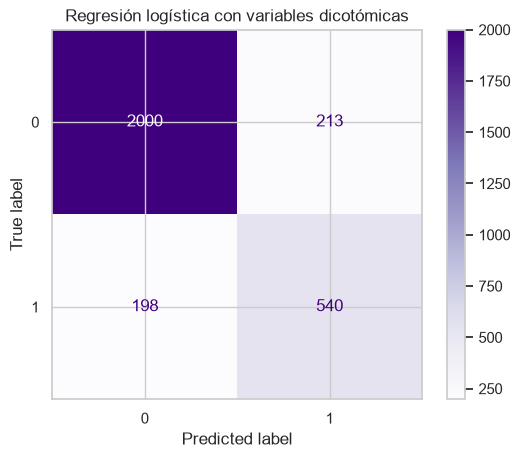

In [17]:
# Odds ratios con intervalo de confianza; se separan las variables con estimación estable de las inestables
or_tab = pd.DataFrame({"coef": logit.params, "odds_ratio": np.exp(logit.params),
                       "IC 2.5%": np.exp(logit.conf_int()[0]), "IC 97.5%": np.exp(logit.conf_int()[1]),
                       "p-value": logit.pvalues, "error estándar": logit.bse}).drop("const")
estables = or_tab[or_tab["error estándar"] < 10].sort_values("odds_ratio", ascending=False)
n_inestables = (or_tab["error estándar"] >= 10).sum()
display(estables.round(4))
print(f"Variables con estimación inestable (separación, no interpretables): {n_inestables}")

# Desempeño del modelo (sobre toda la base, porque aquí no se separó en entrenamiento y prueba)
prob = logit.predict(sm.add_constant(D.astype(float)))
pred = (prob > .5).astype(int)
print("\nAUC:", round(roc_auc_score(y_log, prob), 4))
print(classification_report(y_log, pred, zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(y_log, pred)).plot(cmap="Purples")
plt.title("Regresión logística con variables dicotómicas")
plt.show()

## Análisis de los odds ratios y del desempeño

- La única variable con estimación estable es tener existencias por encima de la mediana: odds ratio de 10.60 con intervalo de confianza de 8.22 a 13.68. Un producto con existencias altas tiene alrededor de 10.6 veces más momios de estar en el 25 % de mayor valor que uno con existencias bajas.
- El intervalo no incluye al 1 y es angosto, así que el efecto es real y está bien estimado.
- Las demás variables, todas de marca, se separan en la tabla porque su estimación es inestable. Para interpretarlas habría que agrupar las marcas con pocos productos en una sola categoría.
- El AUC es de 0.891, bueno, aunque un poco menor al 0.908 de los modelos con existencias continuas. Al convertir las existencias a alto o bajo se pierde información y por eso baja ligeramente la capacidad de discriminar.
- Para la clase de valor alto la precisión es de 0.72 y el recall de 0.73, con un accuracy global de 0.86. El modelo detecta bien tanto a los productos de valor alto como a los de valor bajo, que tienen precisión y recall de 0.91 y 0.90.
- Estas métricas se calcularon sobre toda la base y no sobre datos de prueba, así que son algo más optimistas que las del modelo con partición entrenamiento y prueba.

## Conclusiones generales

- Las existencias son el factor más importante del valor del inventario, tanto en regresión lineal como en logística.
- La marca mejora mucho la explicación del valor: el R cuadrado pasa de 0.37 con el modelo simple a 0.64 con el múltiple.
- Balancear las clases mejora la detección de productos de valor alto frente al modelo base, con una pequeña pérdida de precisión.
- El principal límite es la ausencia del precio unitario en la base. Con esa variable el modelo explicaría casi todo el valor.